<a href="https://colab.research.google.com/github/sahilpalme/Random_Forest/blob/main/Sahil_Pal_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Risk: Loan Default Prediction with Random Forest and SMOTE
Unlox Minor Project | Sahil Pal

**Goal:** predict whether a loan applicant will default (`Loan_Default = 1`).
Same workflow and functions as the class notebook (`LabelEncoder`, one-hot encoding with `get_dummies`, `SMOTE`, `RandomForestClassifier`, `GridSearchCV`), plus the evaluation items the project brief requires: confusion matrix heatmap, precision/recall, F1, ROC-AUC curve, and feature importance.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# folder for high-resolution plots (saved at 300 dpi for the submission)
import os
os.makedirs('plots', exist_ok = True)

## Phase I: Exploratory Data Analysis

In [ ]:
# Choose the credit risk CSV file from your computer (Colab)
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print('Shape:', df.shape)
df.head()

Saving credit_risk_dataset.csv to credit_risk_dataset.csv
Shape: (1500, 8)


,Applicant_ID,Age,Annual_Income,Credit_Score,Employment_Years,Marital_Status,Loan_Amount,Loan_Default
0,10001,56,81934.92,453,29,Divorced,9957.74,0
1,10002,69,57535.86,704,8,Single,1000.00,0
2,10003,46,39807.21,761,34,Married,5246.51,0
3,10004,32,54932.98,431,7,Married,14166.10,1
4,10005,60,53620.39,383,23,Divorced,8705.55,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Applicant_ID      1500 non-null   int64  
 1   Age               1500 non-null   int64  
 2   Annual_Income     1500 non-null   float64
 3   Credit_Score      1500 non-null   int64  
 4   Employment_Years  1500 non-null   int64  
 5   Marital_Status    1500 non-null   object 
 6   Loan_Amount       1500 non-null   float64
 7   Loan_Default      1500 non-null   int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 93.9+ KB


In [ ]:
df.isnull().sum()

,0
Applicant_ID,0
Age,0
Annual_Income,0
Credit_Score,0
Employment_Years,0
Marital_Status,0
Loan_Amount,0
Loan_Default,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Applicant_ID,Age,Annual_Income,Credit_Score,Employment_Years,Loan_Amount,Loan_Default
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,10750.500000,43.732000,55790.464767,577.979333,19.344667,14800.329673,0.220000
std,433.157015,15.071771,20154.492447,156.608247,11.289235,7985.847092,0.414384
min,10001.000000,18.000000,12000.000000,300.000000,0.000000,1000.000000,0.000000
25%,10375.750000,31.000000,42367.987500,443.750000,10.000000,9136.132500,0.000000
50%,10750.500000,44.000000,56046.255000,579.000000,19.000000,14679.220000,0.000000
75%,11125.250000,56.000000,69806.665000,715.000000,29.000000,20239.167500,0.000000
max,11500.000000,69.000000,120092.950000,849.000000,39.000000,40921.110000,1.000000


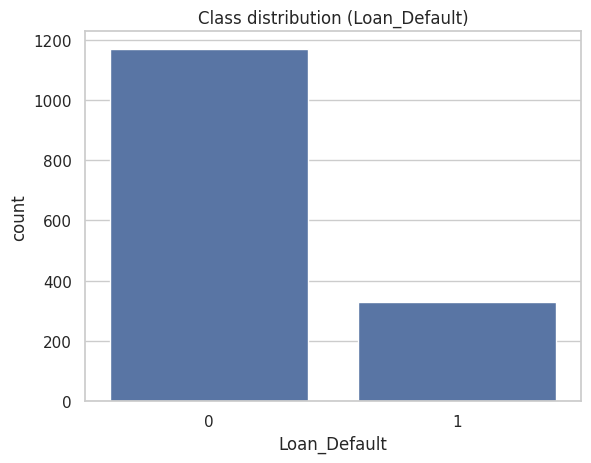

In [ ]:
# Univariate Analysis
sns.countplot(x = 'Loan_Default', data = df)
plt.title('Class distribution (Loan_Default)')
plt.savefig('plots/01_class_distribution.png', dpi = 300, bbox_inches = 'tight')
plt.show()

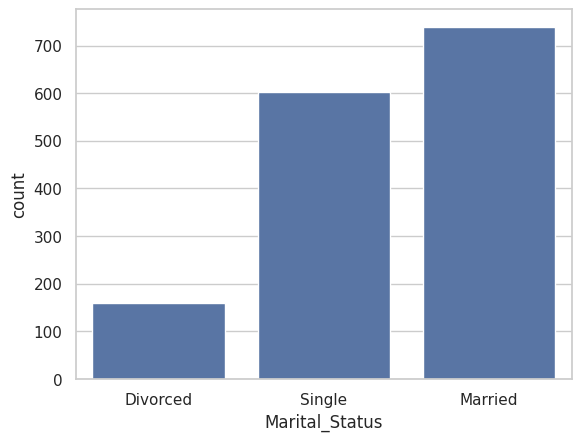

In [ ]:
sns.countplot(x = "Marital_Status", data = df)
plt.savefig('plots/02_marital_status_count.png', dpi = 300, bbox_inches = 'tight')
plt.show()

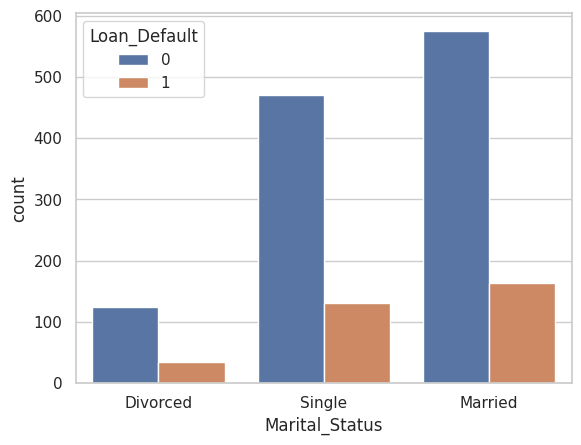

In [ ]:
# Bivariate
sns.countplot(x = 'Marital_Status', hue = 'Loan_Default', data = df)
plt.savefig('plots/03_marital_status_vs_default.png', dpi = 300, bbox_inches = 'tight')
plt.show()

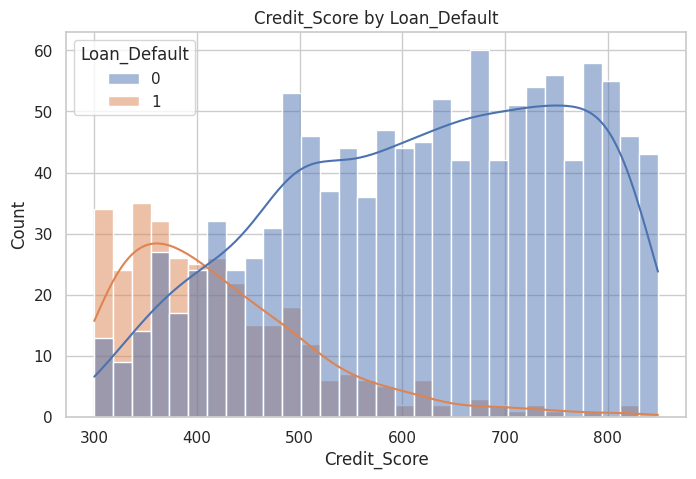

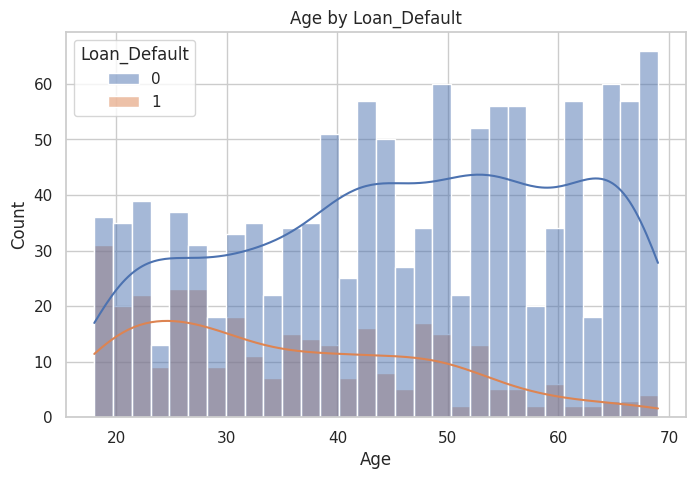

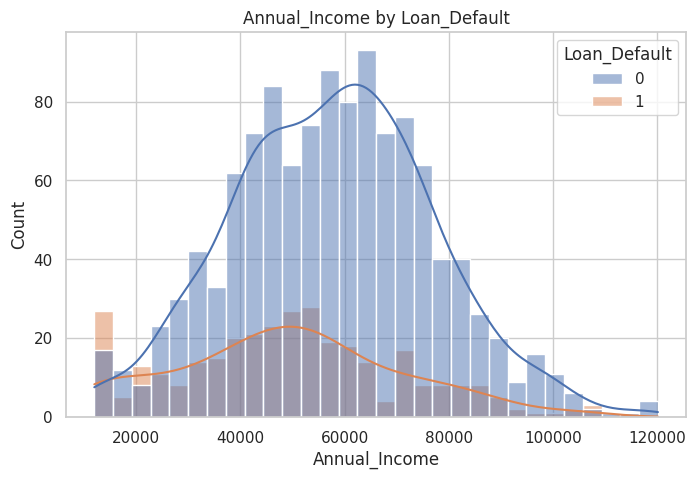

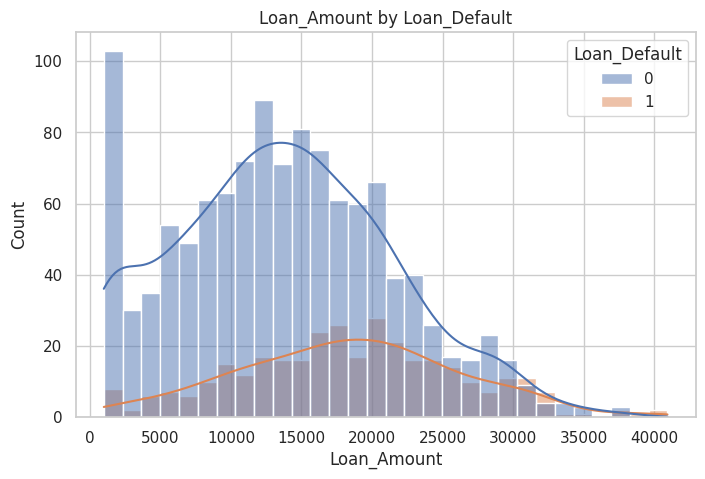

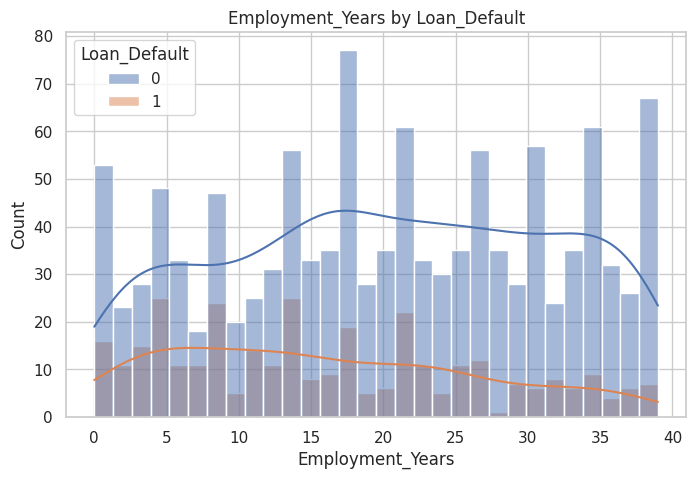

In [ ]:
# Bivariate: numeric features vs default
for col in ["Credit_Score", "Age", "Annual_Income", "Loan_Amount", "Employment_Years"]:
  plt.figure(figsize = (8,5))
  sns.histplot(data = df, x = col, hue = 'Loan_Default', kde = True, bins = 30)
  plt.title(col + ' by Loan_Default')
  plt.savefig(f'plots/04_hist_{col}.png', dpi = 300, bbox_inches = 'tight')
  plt.show()

In [ ]:
# Data sanity check: employment years that cannot fit between age 16 and current age
print((df['Employment_Years'] > df['Age'] - 16).sum(), 'rows have Employment_Years > Age - 16')

504 rows have Employment_Years > Age - 16


## Phase II: Preprocessing

In [ ]:
# Step 1: Missing values (this dataset has none, but the fill is kept as a safeguard)
df = df.fillna(df.median(numeric_only = True))
df.isnull().sum().sum()

np.int64(0)

In [ ]:
# Applicant_ID is just a unique ID (no predictive value), so drop it before encoding
df = df.drop('Applicant_ID', axis = 1)

In [ ]:
# Step 2: Encoding categorical columns
# (a) Label Encoding for columns with only 2 categories
# (b) One-Hot Encoding for columns with 3+ categories (no artificial order is introduced)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
multi_cols = []
for col in df.select_dtypes(include = ['object', 'string']):
  if df[col].nunique() == 2:
    df[col] = le.fit_transform(df[col])
  else:
    multi_cols.append(col)

print('One-hot encoding these columns:', multi_cols)
df = pd.get_dummies(df, columns = multi_cols, dtype = int)
print('Shape after encoding:', df.shape)
df.head()

One-hot encoding these columns: ['Marital_Status']
Shape after encoding: (1500, 9)


,Age,Annual_Income,Credit_Score,Employment_Years,Loan_Amount,Loan_Default,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single
0,56,81934.92,453,29,9957.74,0,1,0,0
1,69,57535.86,704,8,1000.00,0,0,0,1
2,46,39807.21,761,34,5246.51,0,0,1,0
3,32,54932.98,431,7,14166.10,1,0,1,0
4,60,53620.39,383,23,8705.55,0,1,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      1500 non-null   int64  
 1   Annual_Income            1500 non-null   float64
 2   Credit_Score             1500 non-null   int64  
 3   Employment_Years         1500 non-null   int64  
 4   Loan_Amount              1500 non-null   float64
 5   Loan_Default             1500 non-null   int64  
 6   Marital_Status_Divorced  1500 non-null   int64  
 7   Marital_Status_Married   1500 non-null   int64  
 8   Marital_Status_Single    1500 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 105.6 KB


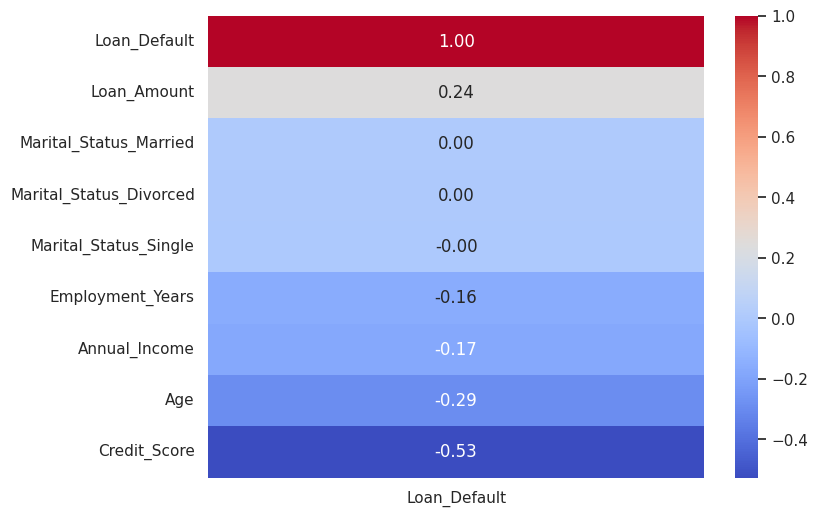

In [ ]:
# Correlation of every feature with Loan_Default
churn_corr = df.corr()
churn_target_corr = churn_corr["Loan_Default"].sort_values(ascending = False)
plt.figure(figsize =(8,6))
sns.heatmap(churn_target_corr.to_frame(), annot = True, cmap = 'coolwarm', fmt = '.2f')
plt.savefig('plots/05_correlation_with_target.png', dpi = 300, bbox_inches = 'tight')
plt.show()

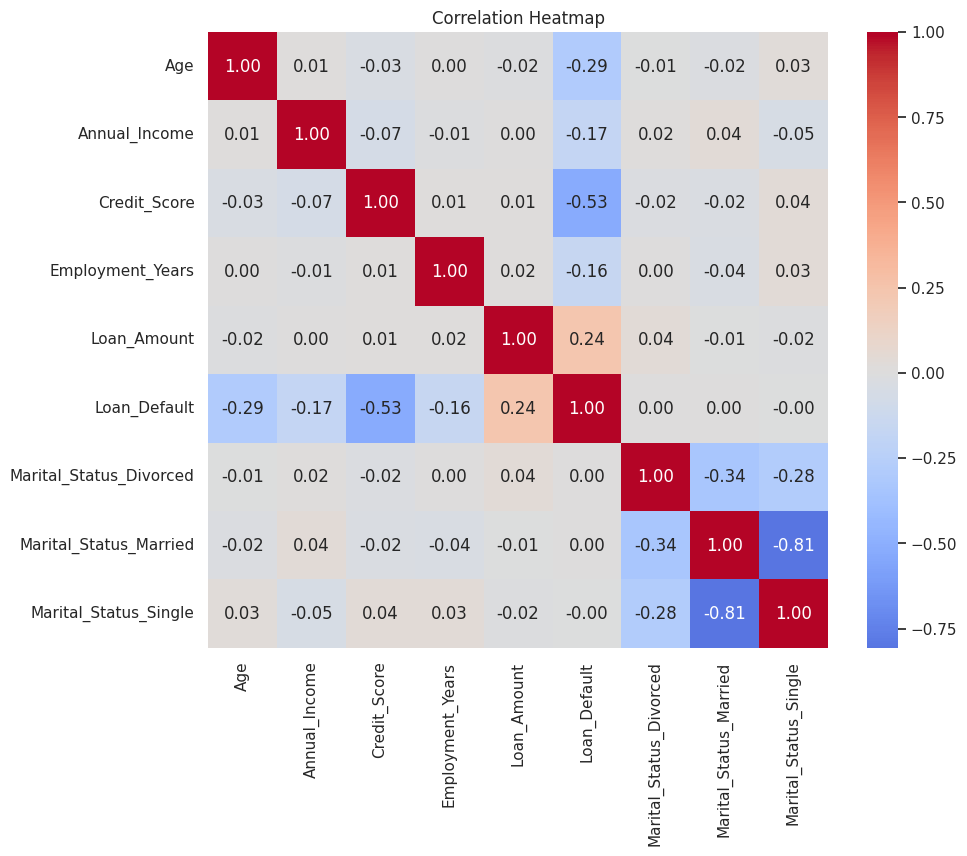

In [ ]:
# Full correlation heatmap (relationships between all variables)
plt.figure(figsize = (10,8))
sns.heatmap(df.corr(), annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0)
plt.title('Correlation Heatmap')
plt.savefig('plots/06_correlation_heatmap.png', dpi = 300, bbox_inches = 'tight')
plt.show()

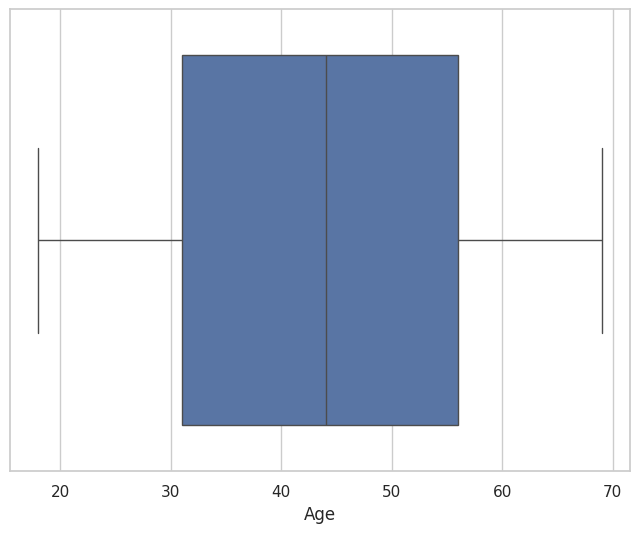

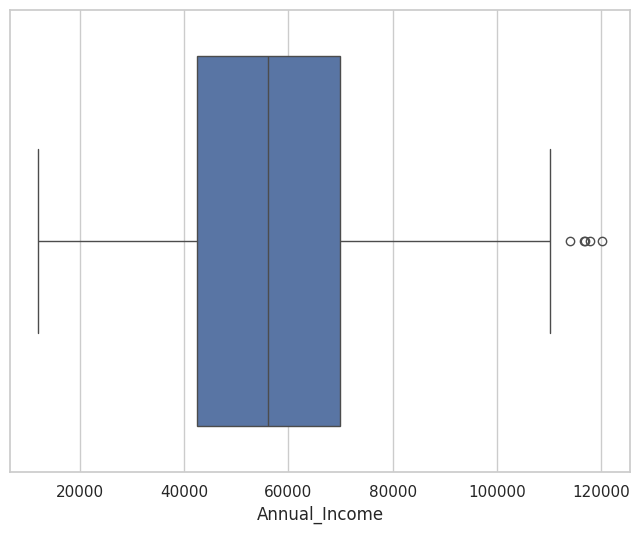

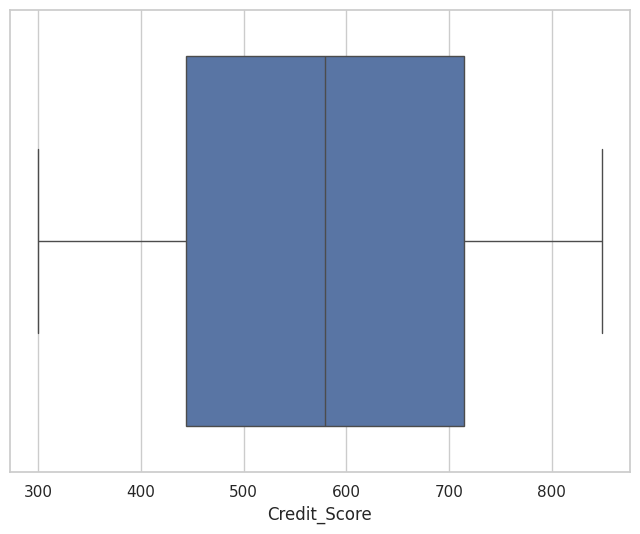

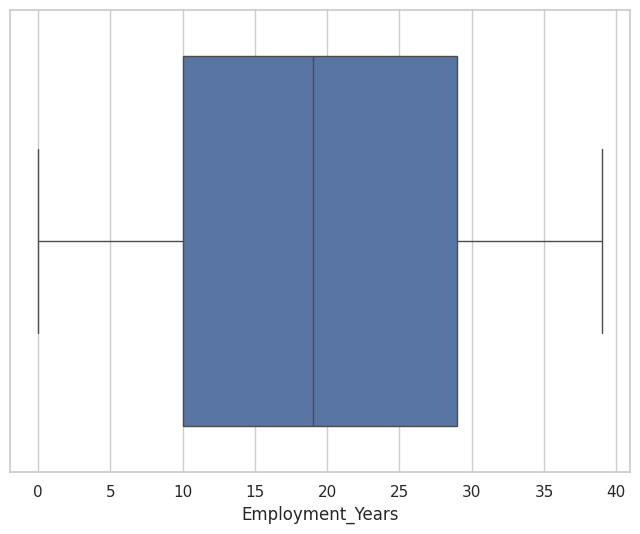

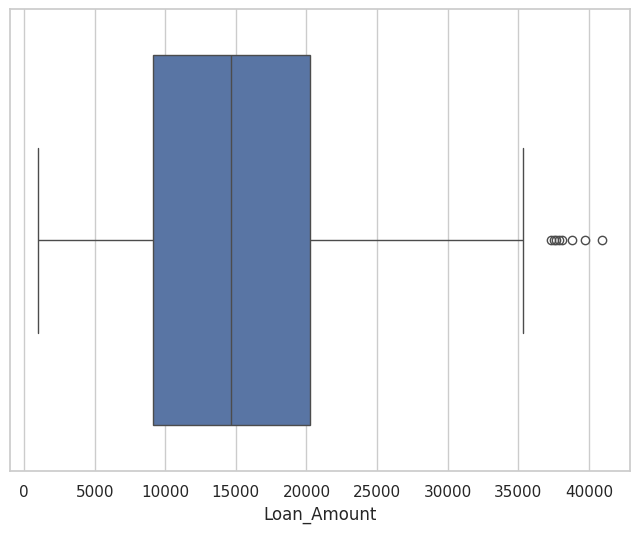

In [ ]:
# Outlier check
cols = ["Age","Annual_Income","Credit_Score","Employment_Years","Loan_Amount"]
for col in cols:
  plt.figure(figsize = (8,6))
  sns.boxplot(x = df[col])
  plt.savefig(f'plots/07_boxplot_{col}.png', dpi = 300, bbox_inches = 'tight')
  plt.show()

In [ ]:
# Imbalance
df["Loan_Default"].value_counts()

,count
Loan_Default,
0,1170
1,330


In [ ]:
df["Loan_Default"].value_counts(normalize= True)*100

,proportion
Loan_Default,
0,78.0
1,22.0


In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop("Loan_Default", axis = 1)
y = df["Loan_Default"]
# stratify = y keeps the same default rate in train and test (useful because the dataset is small)
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state = 42, stratify = y)

In [ ]:
# Smote Technique (applied to the TRAINING data only, so the test set stays untouched and realistic)
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state = 42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [ ]:
print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_train_smote.value_counts())

Before SMOTE: Loan_Default
0    936
1    264
Name: count, dtype: int64
After SMOTE: Loan_Default
1    936
0    936
Name: count, dtype: int64


Feature scaling (`StandardScaler`) is **skipped** on purpose: Random Forest splits on thresholds, so it is not affected by the scale of the features (for example `Annual_Income` vs `Credit_Score`).

## Phase III: Model Development

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state = 42)
model.fit(X_train_smote, y_train_smote)

RandomForestClassifier(random_state=42)

In [ ]:
y_train_pred = model.predict(X_train_smote)
y_test_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train_smote, y_train_pred))
print(accuracy_score(y_test, y_test_pred))

1.0
0.9366666666666666


In [ ]:
# Classification Report (baseline model)
from sklearn.metrics import classification_report
print(classification_report(y_train_smote, y_train_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       936
           1       1.00      1.00      1.00       936

    accuracy                           1.00      1872
   macro avg       1.00      1.00      1.00      1872
weighted avg       1.00      1.00      1.00      1872

              precision    recall  f1-score   support

           0       0.95      0.97      0.96       234
           1       0.90      0.80      0.85        66

    accuracy                           0.94       300
   macro avg       0.92      0.89      0.90       300
weighted avg       0.94      0.94      0.94       300



Compare the training and test scores above. A large gap (high on the SMOTE training data, lower on the test set) is a sign of **overfitting**. Note this in your report, then see whether tuning changes it.

In [ ]:
# hyperparameters
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
model = RandomForestClassifier(random_state = 42)
grid_search = GridSearchCV(estimator = model, param_grid = param_grid, cv = 3, n_jobs = -1, scoring = 'f1')
grid_search.fit(X_train_smote, y_train_smote)

GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200, 300]},
             scoring='f1')

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
0.9628342090205347


In [ ]:
best_model = grid_search.best_estimator_
y_train_pred = best_model.predict(X_train_smote)
y_test_pred = best_model.predict(X_test)
print(accuracy_score(y_train_smote, y_train_pred))
print(accuracy_score(y_test, y_test_pred))

1.0
0.9466666666666667


**Justification of hyperparameters**
- `n_estimators`: more trees reduce variance but give diminishing returns, so the grid compares 50 to 500 and the best value is chosen by 5-fold CV.
- `max_depth`: limiting depth stops trees from memorising noise (overfitting); `None` (unlimited) is included to compare against.
- `min_samples_split` / `min_samples_leaf`: require a minimum number of samples before splitting or in a leaf, which smooths the model.
- `scoring='f1'`: accuracy is misleading on imbalanced data (about 78% of applicants do not default), so the search optimises F1.

## Evaluation (required metrics)

In [ ]:
print(classification_report(y_test, y_test_pred, target_names = ['No default', 'Default']))

              precision    recall  f1-score   support

  No default       0.95      0.98      0.97       234
     Default       0.93      0.82      0.87        66

    accuracy                           0.95       300
   macro avg       0.94      0.90      0.92       300
weighted avg       0.95      0.95      0.95       300



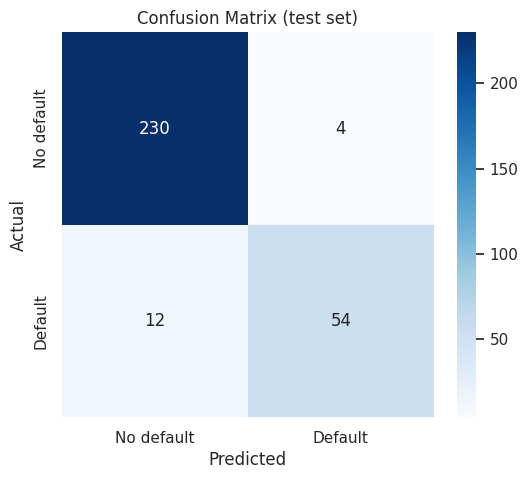

TN: 230 | FP: 4 | FN: 12 | TP: 54


In [ ]:
# 1) Confusion Matrix heatmap
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize = (6,5))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues',
            xticklabels = ['No default','Default'], yticklabels = ['No default','Default'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (test set)')
plt.savefig('plots/08_confusion_matrix.png', dpi = 300, bbox_inches = 'tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print('TN:', tn, '| FP:', fp, '| FN:', fn, '| TP:', tp)

In [ ]:
# 2) Precision, Recall and F1-score
from sklearn.metrics import precision_score, recall_score, f1_score
print('Precision:', round(precision_score(y_test, y_test_pred), 3))
print('Recall   :', round(recall_score(y_test, y_test_pred), 3))
print('F1-score :', round(f1_score(y_test, y_test_pred), 3))

Precision: 0.931
Recall   : 0.818
F1-score : 0.871


**Precision vs recall:** precision = of the applicants flagged as defaulters, how many really default (exactness). Recall = of the applicants who really default, how many we catch (completeness). For lending, a missed defaulter (false negative) means a loss on the loan, while a wrongly flagged good applicant (false positive) means a lost customer and lost interest income. A lender usually prefers higher recall, but pushing recall up lowers precision. F1 is the harmonic mean of the two and is the main score for this imbalanced data.

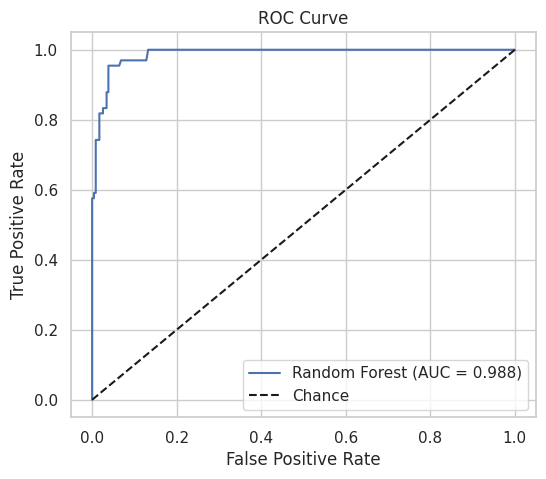

In [ ]:
# 3) ROC curve and AUC
from sklearn.metrics import roc_curve, roc_auc_score
y_prob = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize = (6,5))
plt.plot(fpr, tpr, label = f'Random Forest (AUC = {auc:.3f})')
plt.plot([0,1], [0,1], 'k--', label = 'Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc = 'lower right')
plt.savefig('plots/09_roc_curve.png', dpi = 300, bbox_inches = 'tight')
plt.show()

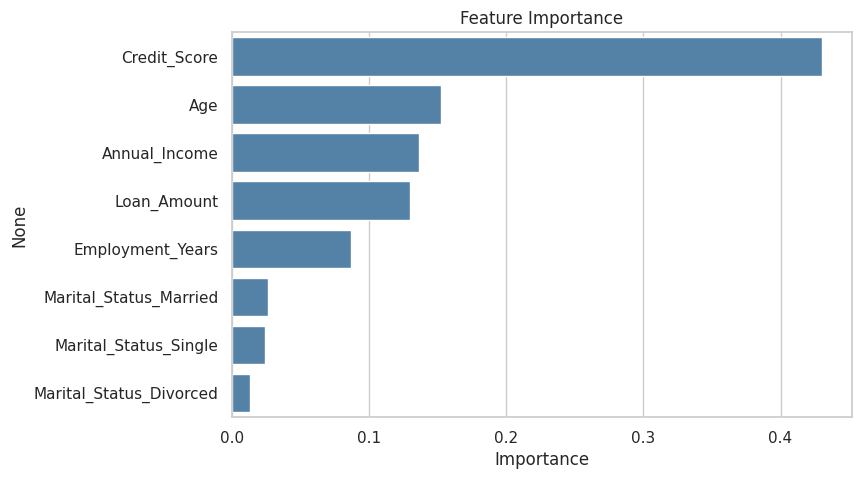

,0
Credit_Score,0.430297
Age,0.152365
Annual_Income,0.136376
Loan_Amount,0.129668
Employment_Years,0.087346
Marital_Status_Married,0.026608
Marital_Status_Single,0.024000
Marital_Status_Divorced,0.013341


In [ ]:
# 4) Feature Importance
importances = pd.Series(best_model.feature_importances_, index = X.columns).sort_values(ascending = False)
plt.figure(figsize = (8,5))
sns.barplot(x = importances.values, y = importances.index, color = 'steelblue')
plt.xlabel('Importance')
plt.title('Feature Importance')
plt.savefig('plots/10_feature_importance.png', dpi = 300, bbox_inches = 'tight')
plt.show()
importances

## Save all plots

In [ ]:
# Zip the plots folder and download it (300 dpi PNG files for the submission)
import shutil
from google.colab import files
shutil.make_archive('plots', 'zip', 'plots')
files.download('plots.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
- **Strengths:** handles mixed features without scaling and is robust to correlated features. Check recall on the default class to see how well SMOTE helped detect defaulters.
- **Weaknesses:** the dataset is small (1,500 rows, so test-set scores are noisy) and has only 6 features, so it lacks things a lender would use (loan purpose, interest rate, existing debts, payment history). Some rows also have `Employment_Years` larger than is possible for the applicant's age. SMOTE interpolates between samples, so it can create fractional values in the one-hot columns, and the model can overfit the synthetic training data.
- **Improvements:** compare SMOTE with `class_weight='balanced'`, try Gradient Boosting (XGBoost / LightGBM), add features such as debt-to-income ratio (`Loan_Amount / Annual_Income`), and choose the decision threshold using the real cost of a default versus a rejected good loan.